In [8]:
import os
# Disables MKL memory conflicts on Windows
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import json
import math
import cv2
import shutil
from PIL import Image
import numpy as np
import tensorflow as tf

from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.callbacks import Callback
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import cohen_kappa_score
from tqdm import tqdm

%matplotlib inline

np.random.seed(2019)
tf.random.set_seed(2019)

Loaded train.csv rows: 0
Augmented DataFrame shape: (0, 2)


,id_code,diagnosis


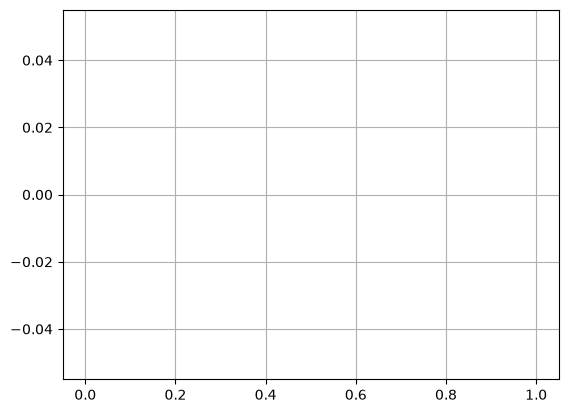

Series([], Name: count, dtype: int64)


In [10]:
import os
import shutil
import pandas as pd
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
import matplotlib.pyplot as plt

# Define your local paths
WORKING_DIR = r"D:\project"
CSV_PATH = r"D:\project\DR_grading.csv"  
IMAGES_DIR = r"D:\project\train_images"   # Folder where your raw images are stored

os.makedirs(os.path.join(WORKING_DIR, 'train_images'), exist_ok=True)

file_path = CSV_PATH
data = pd.read_csv(file_path)

dict_map = {}
LABEL_SIZE = 236

for i in data.index:
    dict_map[data['id_code'][i]] = data['diagnosis'][i]

count = [0, 0, 0, 0, 0]
rows = []

for i in data.index:
    img_id = str(data['id_code'][i])
    
    # Automatically check if the image has .png or .jpg extension on disk
    source_file_path = None
    for ext in ['.png', '.jpg', '.jpeg']:
        test_path = os.path.join(IMAGES_DIR, img_id + ext)
        if os.path.exists(test_path):
            source_file_path = test_path
            actual_filename = img_id + ext
            break
            
    # Fallback if the filename in CSV already includes the extension
    if not source_file_path:
        test_path = os.path.join(IMAGES_DIR, img_id)
        if os.path.exists(test_path):
            source_file_path = test_path
            actual_filename = img_id

    destination_file_path = os.path.join(WORKING_DIR, 'train_images')
    
    if count[data['diagnosis'][i]] < LABEL_SIZE and source_file_path:
        # Save to CSV using the exact filename found on disk
        rows.append([actual_filename, data['diagnosis'][i]])
        shutil.copy(source_file_path, destination_file_path)
        count[data['diagnosis'][i]] += 1

columns = ['id_code', 'diagnosis']
df = pd.DataFrame(rows, columns=columns)

train_csv_path = os.path.join(WORKING_DIR, 'train.csv')
df.to_csv(train_csv_path, index=False)

df1 = pd.read_csv(train_csv_path)
print(f"Loaded train.csv rows: {df1.shape[0]}")

datagen = ImageDataGenerator(
    zoom_range=0.15, 
    fill_mode='constant',
    cval=0.,  
    horizontal_flip=True,  
    vertical_flip=True,
)

aug_images_dir = os.path.join(WORKING_DIR, 'aug_images')
os.makedirs(aug_images_dir, exist_ok=True)

for j in range(df1.shape[0]):
    id_code = df1['id_code'][j]
    diagnosis = str(df1['diagnosis'][j])
    img_path = os.path.join(WORKING_DIR, 'train_images', str(id_code))
    
    if os.path.exists(img_path):
        img = load_img(img_path) 
        x = img_to_array(img)
        x = x.reshape((1, ) + x.shape) 
        
        i = 0
        for batch in datagen.flow(x, batch_size=1, save_to_dir=aug_images_dir, save_prefix=diagnosis + '_', save_format='jpg'):
            i += 1
            if i > 5:
                break

augmented_rows = []
for augmented_img_name in os.listdir(aug_images_dir):
    augmented_rows.append([augmented_img_name, int(augmented_img_name[0])])

df_augmented = pd.DataFrame(augmented_rows, columns=columns)
output_csv_path = os.path.join(WORKING_DIR, 'aug.csv')
df_augmented.to_csv(output_csv_path, index=False)

train_df = pd.read_csv(output_csv_path)
print("Augmented DataFrame shape:", train_df.shape)
display(train_df.head())

train_df['diagnosis'].hist()
plt.show()
print(train_df['diagnosis'].value_counts())

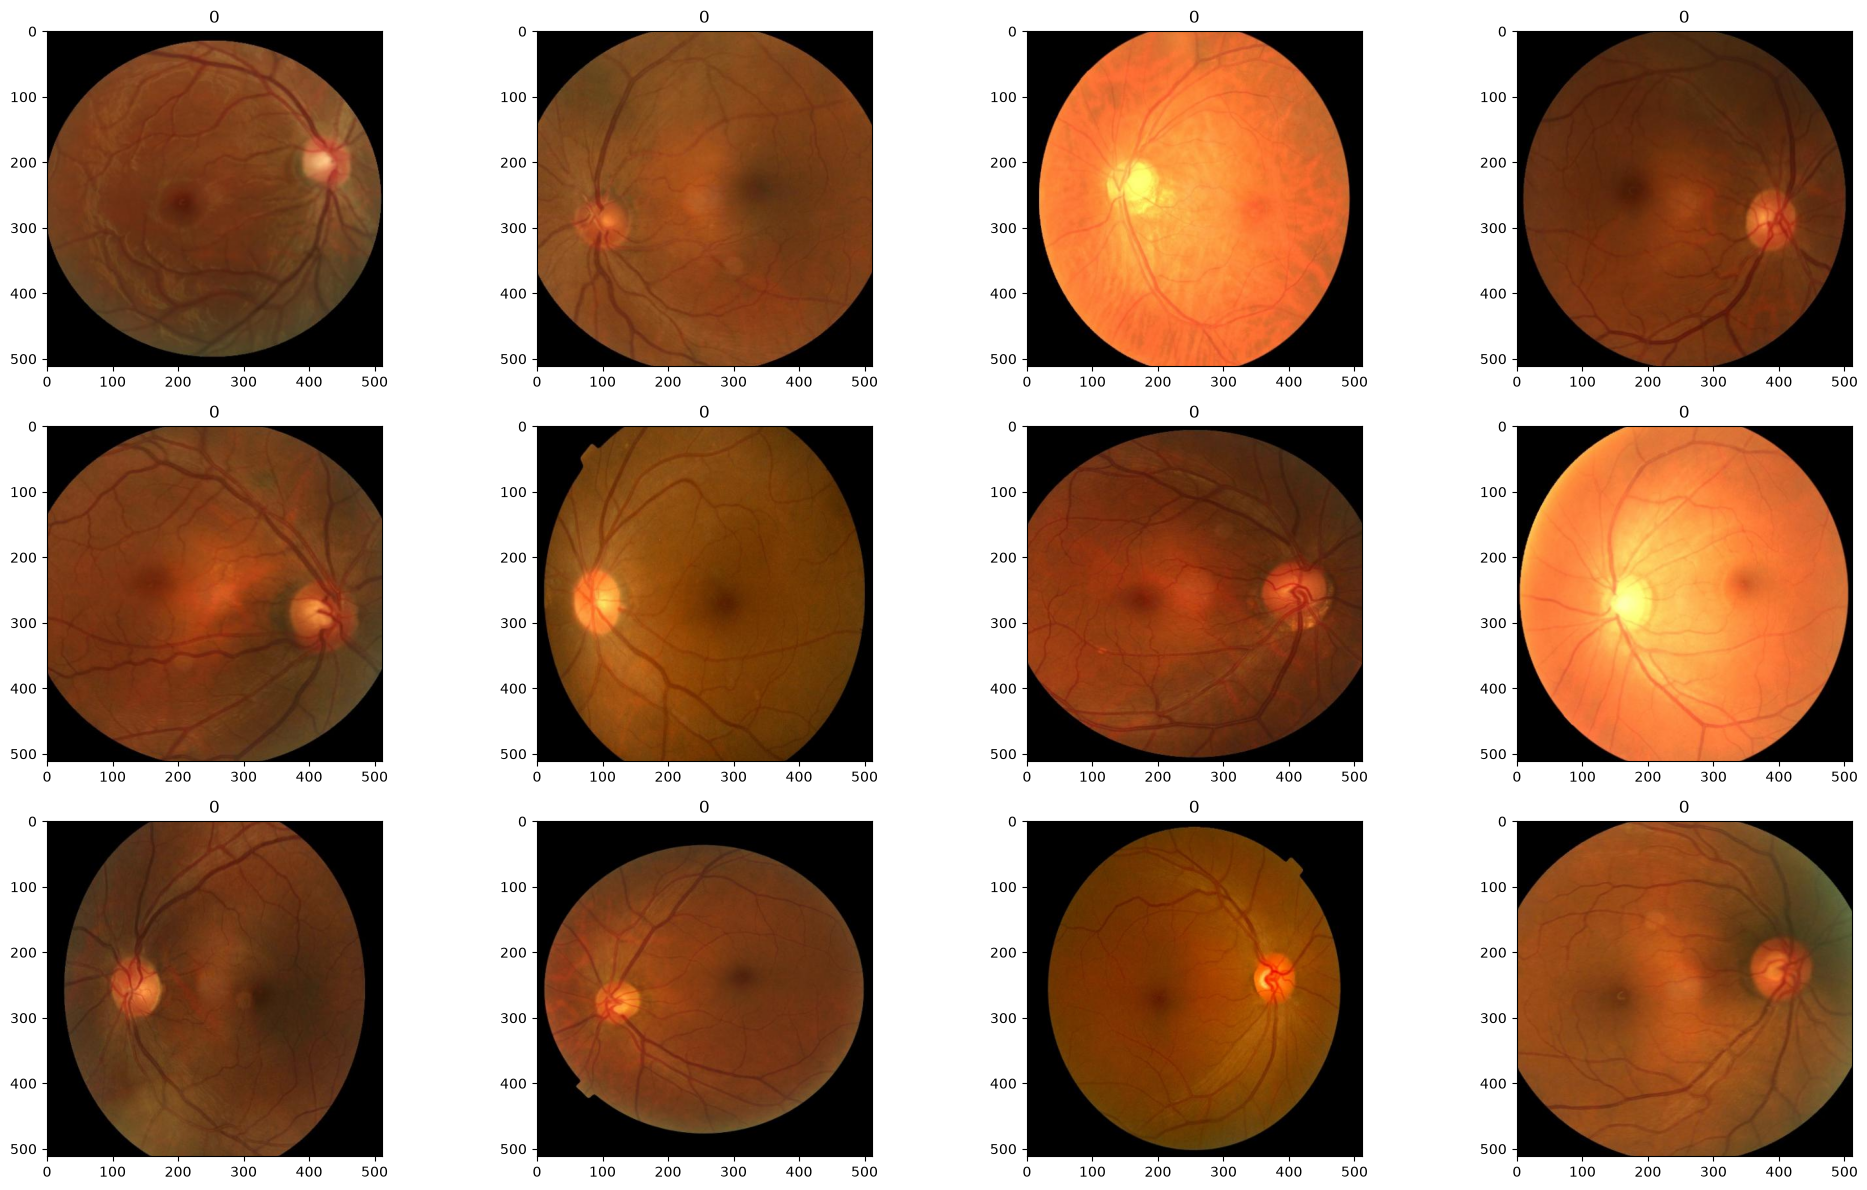

In [ ]:
def display_samples(df, columns=4, rows=3):
    fig = plt.figure(figsize=(5*columns, 4*rows))

    for i in range(columns*rows):
        image_path = df.loc[i, 'id_code']
        image_id = df.loc[i, 'diagnosis']
        
        # Updated local path
        img_full_path = os.path.join(WORKING_DIR, 'aug_images', str(image_path))
        img = cv2.imread(img_full_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        fig.add_subplot(rows, columns, i+1)
        plt.title(image_id)
        plt.imshow(img)
    
    plt.tight_layout()
    plt.show()

display_samples(train_df)

In [ ]:
def get_pad_width(im, new_shape, is_rgb=True):
    pad_diff = new_shape - im.shape[0], new_shape - im.shape[1]
    t, b = math.floor(pad_diff[0]/2), math.ceil(pad_diff[0]/2)
    l, r = math.floor(pad_diff[1]/2), math.ceil(pad_diff[1]/2)
    if is_rgb:
        pad_width = ((t,b), (l,r), (0, 0))
    else:
        pad_width = ((t,b), (l,r))
    return pad_width

def preprocess_image(image_path, desired_size=224):
    im = Image.open(image_path)
    im = im.resize((desired_size, )*2, resample=Image.LANCZOS)
    
    return im

N = train_df.shape[0]
x_train = np.empty((N, 224, 224, 3), dtype=np.uint8)

for i, image_id in enumerate(tqdm(train_df['id_code'])):
    img_path = os.path.join(WORKING_DIR, 'aug_images', str(image_id))
    x_train[i, :, :, :] = preprocess_image(img_path)

y_train = pd.get_dummies(train_df['diagnosis']).values

print(x_train.shape)
print(y_train.shape)

y_train_multi = np.empty(y_train.shape, dtype=y_train.dtype)
y_train_multi[:, 4] = y_train[:, 4]

for i in range(3, -1, -1):
    y_train_multi[:, i] = np.logical_or(y_train[:, i], y_train_multi[:, i+1])

print("Original y_train:", y_train.sum(axis=0))
print("Multilabel version:", y_train_multi.sum(axis=0))

100%|██████████| 6594/6594 [03:08<00:00, 34.94it/s]

(6594, 224, 224, 3)
(6594, 5)
Original y_train: [1308 1318 1329 1321 1318]
Multilabel version: [6594 5286 3968 2639 1318]


In [ ]:
y_train_multi = y_train_multi[:x_train.shape[0]]

x_train_full, x_test, y_train_full, y_test = train_test_split(
    x_train, y_train_multi, 
    test_size=0.2,
    random_state=2019
)

x_train_partial, x_val, y_train_partial, y_val = train_test_split(
    x_train_full, y_train_full, 
    test_size=0.1, 
    random_state=2019
)

BATCH_SIZE = 8

def create_datagen():
    return ImageDataGenerator(
        zoom_range=0.15, 
        fill_mode='constant',
        cval=0.,  
        horizontal_flip=True,  
        vertical_flip=True,  
    )

data_generator = create_datagen().flow(x_train_partial, y_train_partial, batch_size=BATCH_SIZE, seed=2019)

class Metrics(Callback):
    def on_train_begin(self, logs={}):
        self.val_kappas = []

    def on_epoch_end(self, epoch, logs={}):
        val_y = y_val.sum(axis=1) - 1
        
        y_pred = self.model.predict(x_val) > 0.5
        y_pred = y_pred.astype(int).sum(axis=1) - 1

        _val_kappa = cohen_kappa_score(
            val_y,
            y_pred, 
            weights='quadratic'
        )

        self.val_kappas.append(_val_kappa)

        print(f"val_kappa: {_val_kappa:.4f}")
        
        if _val_kappa == max(self.val_kappas):
            print("Validation Kappa has improved. Saving model.")
            self.model.save('model.h5')

        return

densenet = DenseNet121(
    weights='model/DenseNet-BC-121-32-no-top.h5',
    include_top=False,
    input_shape=(224, 224, 3)
)

def build_model():
    model = Sequential()
    model.add(densenet)
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(5, activation='sigmoid'))
    
    model.compile(
        loss='binary_crossentropy',
        optimizer=Adam(learning_rate=0.00005),
        metrics=['accuracy']
    )
    
    return model

model = build_model()
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         5,125 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,042,629 (26.87 MB)

 Trainable params: 6,958,981 (26.55 MB)

 Non-trainable params: 83,648 (326.75 KB)

In [ ]:
import gc
gc.collect()

kappa_metrics = Metrics()

BATCH_SIZE = 8

history = model.fit(
    data_generator,
    steps_per_epoch=int(len(x_train_partial) / BATCH_SIZE),
    epochs=9,
    validation_data=(x_val, y_val),
    callbacks=[kappa_metrics]
)

model.save('densenet.keras')

y_pred = model.predict(x_test) > 0.5
y_pred = y_pred.astype(int).sum(axis=1) - 1

y_true = y_test.sum(axis=1) - 1

with open('history.json', 'w') as f:
    json.dump(history.history, f)

history_df = pd.DataFrame(history.history)

# Plot loss
history_df[['loss', 'val_loss']].plot()
plt.title('Model Loss')
plt.show()

# Plot accuracy
history_df[['accuracy', 'val_accuracy']].plot()
plt.title('Model Accuracy')
plt.show()

Epoch 1/9
  3/593 ━━━━━━━━━━━━━━━━━━━━ 25:24 3s/step - accuracy: 0.0833 - loss: 0.9019 

AbortedError: Graph execution error:

Detected at node StatefulPartitionedCall/sequential_1_1/densenet121_1/pool4_conv_1/convolution defined at (most recent call last):
<stack traces unavailable>
Operation received an exception:Status: 1, message: could not create a memory object, in file tensorflow/core/kernels/mkl/mkl_conv_ops.cc:1112
	 [[{{node StatefulPartitionedCall/sequential_1_1/densenet121_1/pool4_conv_1/convolution}}]] [Op:__inference_multi_step_on_iterator_181319]